In [14]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D


In [15]:
seed = 42

def random_number():
    global seed
    seed = (16807 * seed) % 2147483647
    return seed / 2147483647


def random_index(n):
    return min(int(random_number() * n), n - 1)


def shuffle_indices(n):
    indices = list(range(n))

    for i in range(n - 1, 0, -1):
        j = random_index(i + 1)
        indices[i], indices[j] = indices[j], indices[i]

    return np.array(indices)

In [16]:
def box_muller(n):
    z = np.zeros((n, 2), dtype=float)

    for i in range(n):
        
        u1 = max(random_number(), 1e-12)
        u2 = random_number()

        r = np.sqrt(-2 * np.log(u1))
        theta = 2 * np.pi * u2

        z[i, 0] = r * np.cos(theta)
        z[i, 1] = r * np.sin(theta)

    return z


In [17]:
def generate_gaussian(n, mean, covariance_type,
                      sigma_x=1.0, sigma_y=0.75, rho=0.60):
    if sigma_x <= 0 or sigma_y <= 0:
        raise ValueError("sigma_x and sigma_y must be positive.")
    if not -1 < rho < 1:
        raise ValueError("rho must be strictly between -1 and 1.")
    if covariance_type not in {"Isotropic", "diagonal", "full"}:
        raise ValueError("covariance_type must be Isotropic, diagonal, or full.")

    z = box_muller(n)
    x = np.zeros((n, 2), dtype=float)

    if covariance_type == "Isotropic":
        x[:, 0] = mean[0] + sigma_x * z[:, 0]
        x[:, 1] = mean[1] + sigma_x * z[:, 1]

    elif covariance_type == "diagonal":
        x[:, 0] = mean[0] + sigma_x * z[:, 0]
        x[:, 1] = mean[1] + sigma_y * z[:, 1]

    elif covariance_type == "full":
        x[:, 0] = mean[0] + sigma_x * z[:, 0]
        x[:, 1] = mean[1] + sigma_y * (
            rho * z[:, 0] + np.sqrt(1 - rho**2) * z[:, 1]
        )

    return x


In [18]:
K = 3
n_samples = 1500



pi_k = np.array([0.2, 0.3, 0.5], dtype=float)

if len(pi_k) != K or np.any(pi_k < 0) or not np.isclose(pi_k.sum(), 1.0):
    raise ValueError("pi_k must contain K non-negative probabilities that sum to 1.")


weights_class1 = pi_k.copy()
weights_class2 = pi_k.copy()


bounds = np.cumsum(pi_k)


means_class1 = np.array([
    [3, 2],
    [3, 5],
    [3, 8]
], dtype=float)

means_class2 = np.array([
    [9, 2],
    [9, 5],
    [9, 8]
], dtype=float)

sigma_x = 1.0
sigma_y = 0.75
rho = 0.60

covariance_types = [
    "Isotropic",
    "diagonal",
    "full"
]

class_colors = ["blue", "red"]
component_colors = ["seagreen", "darkorange", "violet"]

print("Mixture probabilities (pi_k):", pi_k)
print("Cumulative probability boundaries:", np.round(bounds, 4))
print("Probability sum:", pi_k.sum())
print("\nUniform intervals:")
for k in range(K):
    lower = 0.0 if k == 0 else bounds[k - 1]
    upper = bounds[k]
    right_bracket = "]" if k == K - 1 else ")"
    print(f"Mixture {k + 1}: U in [{lower:.1f}, {upper:.1f}{right_bracket}")



print("\nExample LCG Uniform values and selected mixtures:")
for _ in range(10):
    u = random_number()
    component = min(np.searchsorted(bounds, u, side="right"), K - 1)
    print(f"U = {u:.4f} -> Mixture {component + 1}")


Mixture probabilities (pi_k): [0.2 0.3 0.5]
Cumulative probability boundaries: [0.2 0.5 1. ]
Probability sum: 1.0

Uniform intervals:
Mixture 1: U in [0.0, 0.2)
Mixture 2: U in [0.2, 0.5)
Mixture 3: U in [0.5, 1.0]

Example LCG Uniform values and selected mixtures:
U = 0.0003 -> Mixture 1
U = 0.5246 -> Mixture 3
U = 0.7354 -> Mixture 3
U = 0.2633 -> Mixture 2
U = 0.3762 -> Mixture 2
U = 0.1963 -> Mixture 1
U = 0.9759 -> Mixture 3
U = 0.5123 -> Mixture 3
U = 0.5304 -> Mixture 3
U = 0.2571 -> Mixture 2


In [19]:
def generate_gmm(n, means, weights, covariance_type):
    weights = np.asarray(weights, dtype=float)
    means = np.asarray(means, dtype=float)

    if len(weights) != len(means):
        raise ValueError("The number of mixture weights must match the number of means.")
    if np.any(weights < 0) or not np.isclose(weights.sum(), 1.0):
        raise ValueError("Mixture weights must be non-negative and sum to 1.")

    
    cumulative_weights = np.cumsum(weights)
    cumulative_weights[-1] = 1.0

    
    selection_uniforms = np.array([random_number() for _ in range(n)], dtype=float)
    component_indices = np.searchsorted(cumulative_weights, selection_uniforms, side="right")
    component_indices = np.minimum(component_indices, len(weights) - 1)

    X = np.zeros((n, 2), dtype=float)

    
    for j in range(len(means)):
        mask = component_indices == j
        count = int(np.sum(mask))
        if count:
            X[mask] = generate_gaussian(
                count,
                means[j],
                covariance_type,
                sigma_x,
                sigma_y,
                rho
            )

    return X, component_indices, selection_uniforms



Isotropic covariance — Uniform and mixture counts
Total samples: Class 1 = 1500, Class 2 = 1500, combined = 3000
Uniform draws for mixture selection: Class 1 = 1500, Class 2 = 1500, total = 3000
Uniform draws for Box-Muller: 6000
Total Uniform(0, 1) draws for this covariance type: 9000
Class 1 counts per mixture: [304 481 715] (total: 1500 )
Class 2 counts per mixture: [302 447 751] (total: 1500 )
Combined counts per mixture: [ 606  928 1466] (total: 3000 )

Diagonal covariance — Uniform and mixture counts
Total samples: Class 1 = 1500, Class 2 = 1500, combined = 3000
Uniform draws for mixture selection: Class 1 = 1500, Class 2 = 1500, total = 3000
Uniform draws for Box-Muller: 6000
Total Uniform(0, 1) draws for this covariance type: 9000
Class 1 counts per mixture: [307 419 774] (total: 1500 )
Class 2 counts per mixture: [306 446 748] (total: 1500 )
Combined counts per mixture: [ 613  865 1522] (total: 3000 )

Full covariance — Uniform and mixture counts
Total samples: Class 1 = 1500

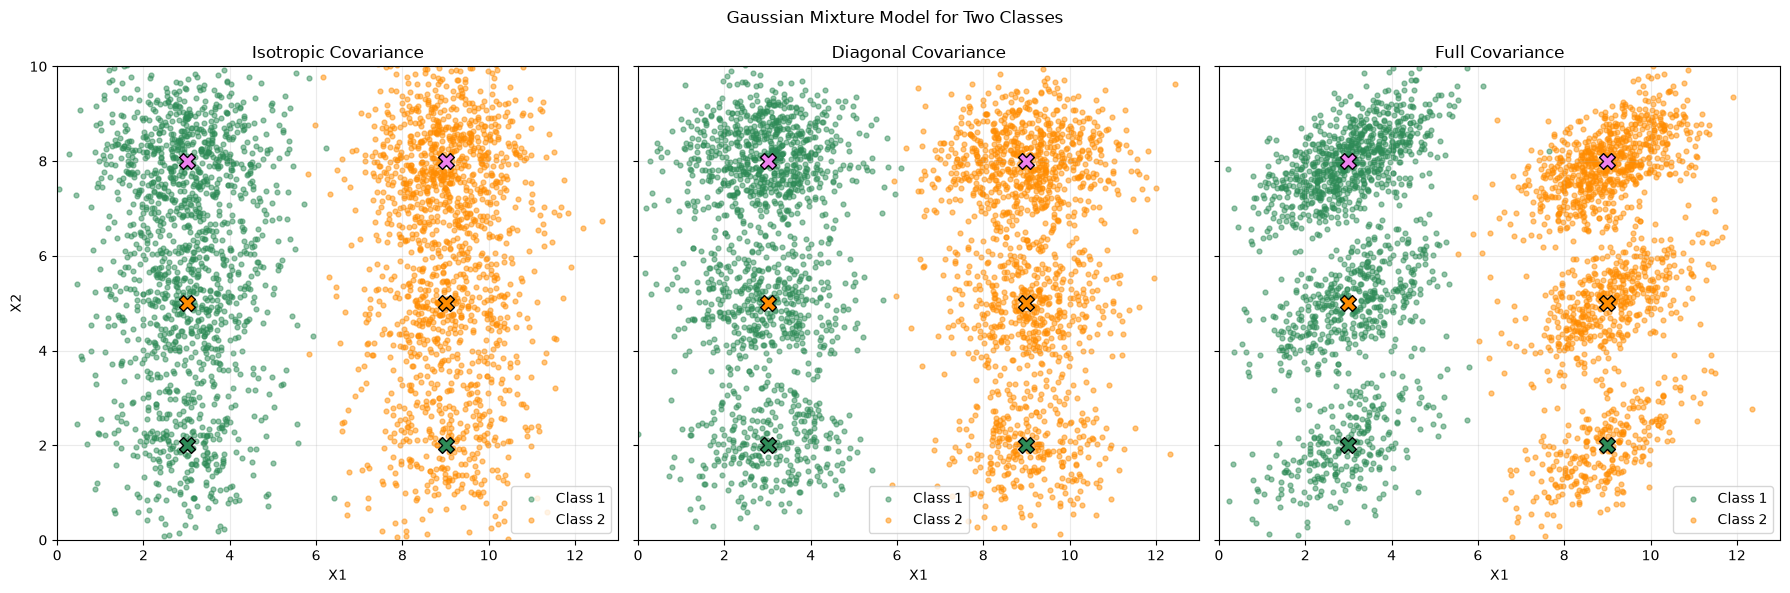

In [20]:
fig, axes = plt.subplots(1, 3, figsize=(18, 6), sharex=True, sharey=True)

uniform_count_summary = []

for ax, cov_type in zip(axes, covariance_types):

    X1, comp1, u1 = generate_gmm(
        n_samples, means_class1,
        weights_class1, cov_type
    )

    X2, comp2, u2 = generate_gmm(
        n_samples, means_class2,
        weights_class2, cov_type
    )

    
    counts_class1 = np.bincount(comp1, minlength=K)
    counts_class2 = np.bincount(comp2, minlength=K)

    
    selection_uniform_count = len(u1) + len(u2)
    box_muller_uniform_count = 2 * (len(X1) + len(X2))
    total_uniform_count = selection_uniform_count + box_muller_uniform_count

    uniform_count_summary.append({
        "Covariance": cov_type,
        "Class 1 selection U count": len(u1),
        "Class 2 selection U count": len(u2),
        "Total mixture-selection U": selection_uniform_count,
        "Box-Muller U count": box_muller_uniform_count,
        "Total Uniform draws": total_uniform_count,
        "Class 1 M1": int(counts_class1[0]),
        "Class 1 M2": int(counts_class1[1]),
        "Class 1 M3": int(counts_class1[2]),
        "Class 2 M1": int(counts_class2[0]),
        "Class 2 M2": int(counts_class2[1]),
        "Class 2 M3": int(counts_class2[2]),
    })

    print(f"\n{cov_type.title()} covariance — Uniform and mixture counts")
    print(f"Total samples: Class 1 = {len(X1)}, Class 2 = {len(X2)}, combined = {len(X1) + len(X2)}")
    print(f"Uniform draws for mixture selection: Class 1 = {len(u1)}, Class 2 = {len(u2)}, total = {selection_uniform_count}")
    print(f"Uniform draws for Box-Muller: {box_muller_uniform_count}")
    print(f"Total Uniform(0, 1) draws for this covariance type: {total_uniform_count}")
    print("Class 1 counts per mixture:", counts_class1, "(total:", counts_class1.sum(), ")")
    print("Class 2 counts per mixture:", counts_class2, "(total:", counts_class2.sum(), ")")
    print("Combined counts per mixture:", counts_class1 + counts_class2,
          "(total:", (counts_class1 + counts_class2).sum(), ")")

    ax.scatter(
        X1[:, 0], X1[:, 1],
        s=12, color="seagreen",
        alpha=0.5, label="Class 1"
    )

    ax.scatter(
        X2[:, 0], X2[:, 1],
        s=12, color="darkorange",
        alpha=0.5, label="Class 2"
    )

    for j in range(K):
        m1 = means_class1[j]
        m2 = means_class2[j]

        ax.scatter(
            m1[0], m1[1],
            marker="X", s=130,
            color=component_colors[j],
            edgecolor="black", zorder=3
        )

        ax.scatter(
            m2[0], m2[1],
            marker="X", s=130,
            color=component_colors[j],
            edgecolor="black", zorder=3
        )

    ax.set_title(f"{cov_type.title()} Covariance")
    ax.set_xlabel("X1")
    ax.set_xlim(0, 13)
    ax.set_ylim(0, 10)
    ax.grid(alpha=0.25)
    ax.legend()

axes[0].set_ylabel("X2")

print("\nSummary table (one generation pass per covariance type):")
print(uniform_count_summary)

plt.suptitle("Gaussian Mixture Model for Two Classes")
plt.tight_layout()
plt.show()


In [21]:
def train_test_split(X, train_ratio=0.8):
    indices = shuffle_indices(len(X))
    split_point = int(train_ratio * len(X))

    train_indices = indices[:split_point]
    test_indices = indices[split_point:]

    return X[train_indices], X[test_indices]


datasets = {}

for cov_type in covariance_types:

    X1, comp1, _ = generate_gmm(
        n_samples, means_class1,
        weights_class1, cov_type
    )

    X2, comp2, _ = generate_gmm(
        n_samples, means_class2,
        weights_class2, cov_type
    )

    X1_train, X1_test = train_test_split(X1)
    X2_train, X2_test = train_test_split(X2)

    datasets[cov_type] = {
        "X1_train": X1_train,
        "X1_test": X1_test,
        "X2_train": X2_train,
        "X2_test": X2_test
    }

    print(cov_type.title())
    print("Class 1 training:", len(X1_train))
    print("Class 1 testing:", len(X1_test))
    print("Class 2 training:", len(X2_train))
    print("Class 2 testing:", len(X2_test))
    print()

Isotropic
Class 1 training: 1200
Class 1 testing: 300
Class 2 training: 1200
Class 2 testing: 300

Diagonal
Class 1 training: 1200
Class 1 testing: 300
Class 2 training: 1200
Class 2 testing: 300

Full
Class 1 training: 1200
Class 1 testing: 300
Class 2 training: 1200
Class 2 testing: 300



In [22]:
def kmeans(X, k, max_iterations=100):

    indices = shuffle_indices(len(X))
    centroids = X[indices[:k]].copy()

    for iteration in range(max_iterations):

        distances = np.zeros((len(X), k))

        for j in range(k):
            distances[:, j] = np.sum(
                (X - centroids[j]) ** 2,
                axis=1
            )

        labels = np.argmin(distances, axis=1)
        new_centroids = centroids.copy()

        for j in range(k):
            points = X[labels == j]

            if len(points) > 0:
                new_centroids[j] = np.mean(
                    points, axis=0
                )

        difference = np.sum(
            (new_centroids - centroids) ** 2
        )

        centroids = new_centroids

        if difference < 1e-8:
            break

    distances = np.zeros((len(X), k))

    for j in range(k):
        distances[:, j] = np.sum(
            (X - centroids[j]) ** 2,
            axis=1
        )

    labels = np.argmin(distances, axis=1)

    return centroids, labels

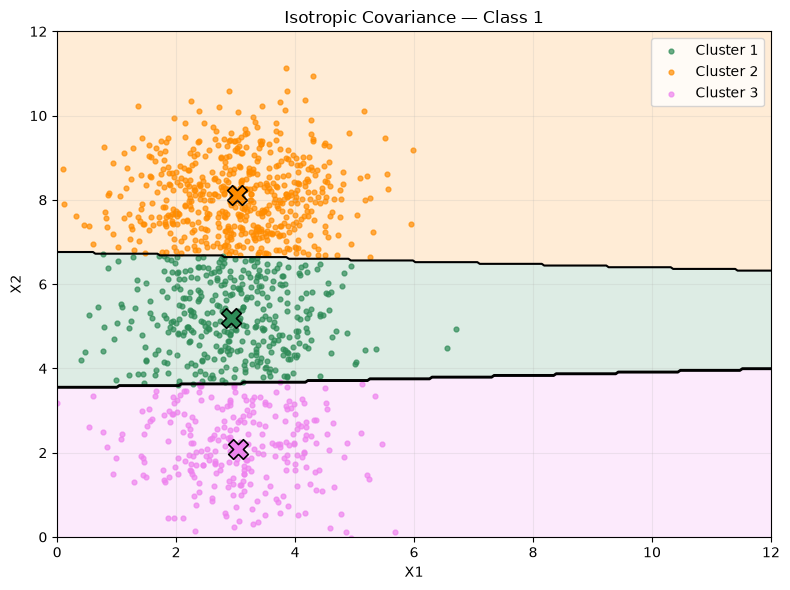

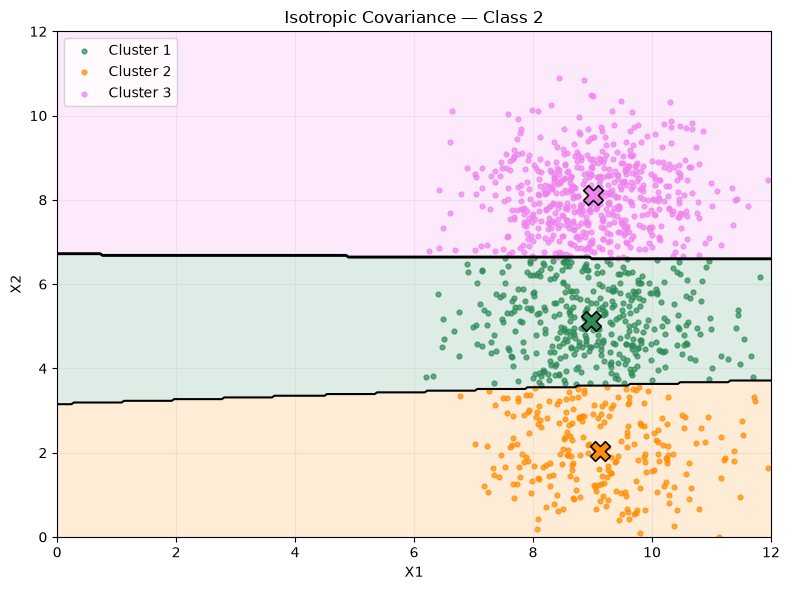

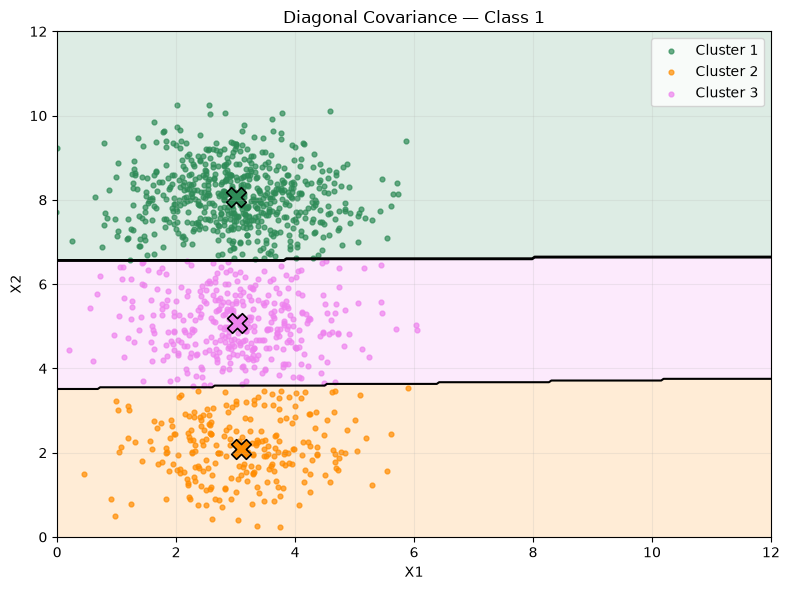

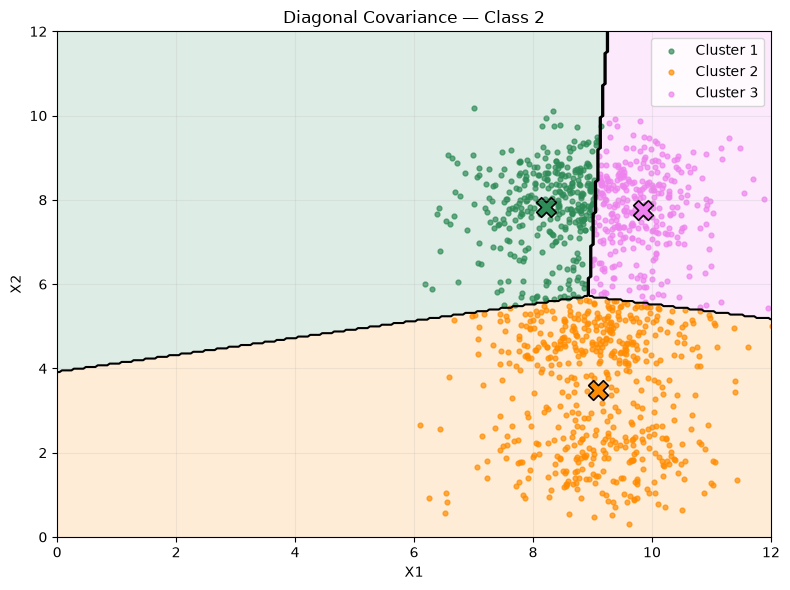

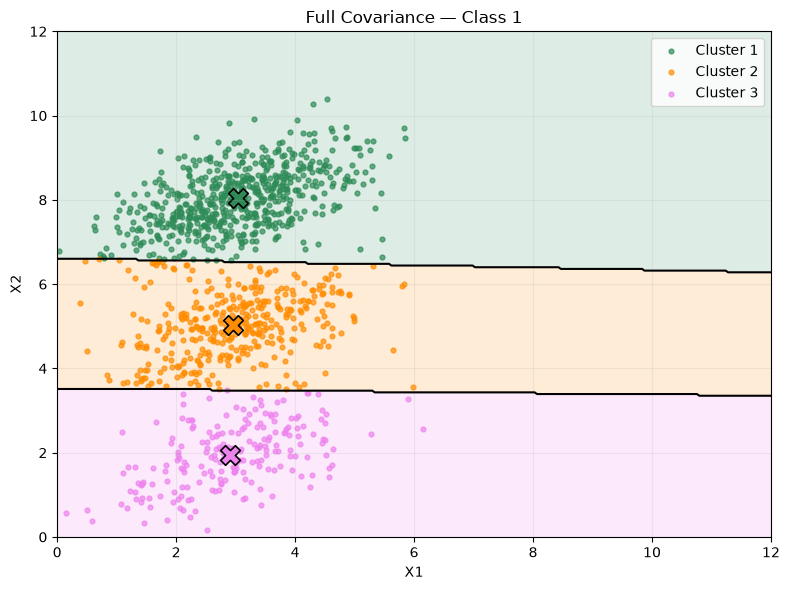

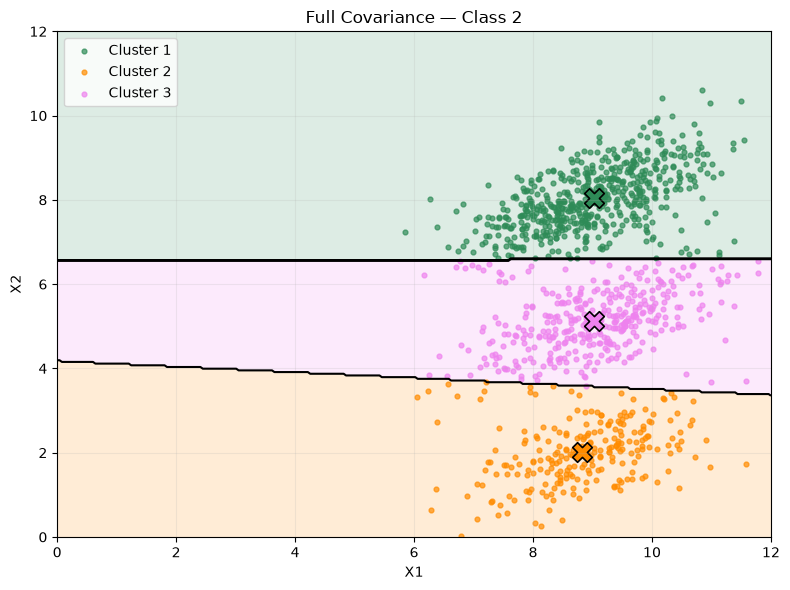

In [23]:
def plot_kmeans_clusters(X, centroids, labels, title):

    x_min, x_max = 0, 12
    y_min, y_max = 0, 12

    xx, yy = np.meshgrid(
        np.linspace(x_min, x_max, 300),
        np.linspace(y_min, y_max, 300)
    )

    grid = np.column_stack((
        xx.ravel(), yy.ravel()
    ))

    distances = np.zeros((len(grid), K))

    for j in range(K):
        distances[:, j] = np.sum(
            (grid - centroids[j]) ** 2,
            axis=1
        )

    regions = np.argmin(
        distances, axis=1
    ).reshape(xx.shape)

    plt.figure(figsize=(8, 6))

    plt.contourf(
        xx, yy, regions,
        levels=[-0.5, 0.5, 1.5, 2.5],
        colors=component_colors,
        alpha=0.16
    )

    plt.contour(
        xx, yy, regions,
        levels=[0.5, 1.5],
        colors="black",
        linewidths=1.5
    )

    for j in range(K):

        points = X[labels == j]

        plt.scatter(
            points[:, 0], points[:, 1],
            s=12,
            color=component_colors[j],
            alpha=0.7,
            label=f"Cluster {j+1}"
        )

        plt.scatter(
            centroids[j, 0], centroids[j, 1],
            marker="X",
            s=200,
            color=component_colors[j],
            edgecolor="black",
            linewidth=1.2
        )

    plt.title(title)
    plt.xlabel("X1")
    plt.ylabel("X2")

    plt.xlim(0, 12)
    plt.ylim(0, 12)

    plt.xticks(np.arange(0, 13, 2))
    plt.yticks(np.arange(0, 13, 2))

    plt.legend()
    plt.grid(alpha=0.2)
    plt.tight_layout()
    plt.show()


cluster_results = {}

for cov_type in covariance_types:

    X1_train = datasets[cov_type]["X1_train"]
    X2_train = datasets[cov_type]["X2_train"]

    centroids1, labels1 = kmeans(X1_train, K)
    centroids2, labels2 = kmeans(X2_train, K)

    cluster_results[cov_type] = {
        "centroids1": centroids1,
        "centroids2": centroids2,
        "labels1": labels1,
        "labels2": labels2
    }

    plot_kmeans_clusters(
        X1_train,
        centroids1,
        labels1,
        f"{cov_type.title()} Covariance — Class 1"
    )

    plot_kmeans_clusters(
        X2_train,
        centroids2,
        labels2,
        f"{cov_type.title()} Covariance — Class 2"
    )

In [24]:
def calculate_distortion(X, centroids):

    distances = np.zeros(
        (len(X), len(centroids))
    )

    for j in range(len(centroids)):
        distances[:, j] = np.sum(
            (X - centroids[j]) ** 2,
            axis=1
        )

    return np.min(distances, axis=1)


def classify_by_distortion(
    X, centroids1, centroids2
):

    distortion1 = calculate_distortion(
        X, centroids1
    )

    distortion2 = calculate_distortion(
        X, centroids2
    )

    predictions = np.where(
        distortion1 <= distortion2, 0, 1
    )

    return predictions, distortion1, distortion2


results = {}

for cov_type in covariance_types:

    X1_test = datasets[cov_type]["X1_test"]
    X2_test = datasets[cov_type]["X2_test"]

    X_test = np.vstack((
        X1_test, X2_test
    ))

    y_test = np.concatenate((
        np.zeros(len(X1_test), dtype=int),
        np.ones(len(X2_test), dtype=int)
    ))

    centroids1 = cluster_results[cov_type][
        "centroids1"
    ]

    centroids2 = cluster_results[cov_type][
        "centroids2"
    ]

    predictions, d1, d2 = classify_by_distortion(
        X_test, centroids1, centroids2
    )

    accuracy = np.mean(
        predictions == y_test
    ) * 100

    confusion = np.zeros((2, 2), dtype=int)

    for actual, predicted in zip(
        y_test, predictions
    ):
        confusion[actual, predicted] += 1

    results[cov_type] = {
        "accuracy": accuracy,
        "confusion": confusion,
        "predictions": predictions,
        "y_test": y_test,
        "X_test": X_test,
        "distortion1": d1,
        "distortion2": d2
    }

    print("=" * 50)
    print("Covariance:", cov_type.title())
    print(f"Test accuracy: {accuracy:.2f}%")
    print("Confusion matrix:")
    print(confusion)
    print("Correct predictions:",
          np.sum(predictions == y_test))
    print("Incorrect predictions:",
          np.sum(predictions != y_test))

Covariance: Isotropic
Test accuracy: 99.67%
Confusion matrix:
[[299   1]
 [  1 299]]
Correct predictions: 598
Incorrect predictions: 2
Covariance: Diagonal
Test accuracy: 99.83%
Confusion matrix:
[[300   0]
 [  1 299]]
Correct predictions: 599
Incorrect predictions: 1
Covariance: Full
Test accuracy: 100.00%
Confusion matrix:
[[300   0]
 [  0 300]]
Correct predictions: 600
Incorrect predictions: 0


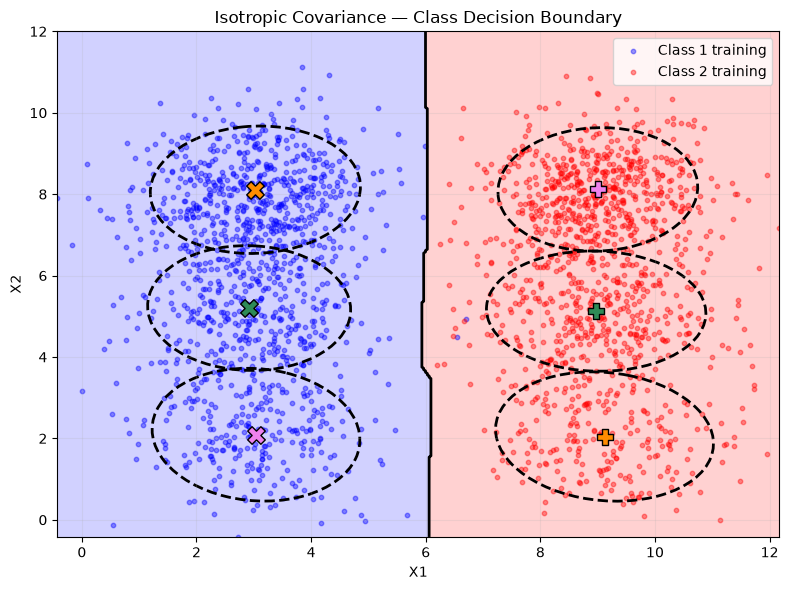

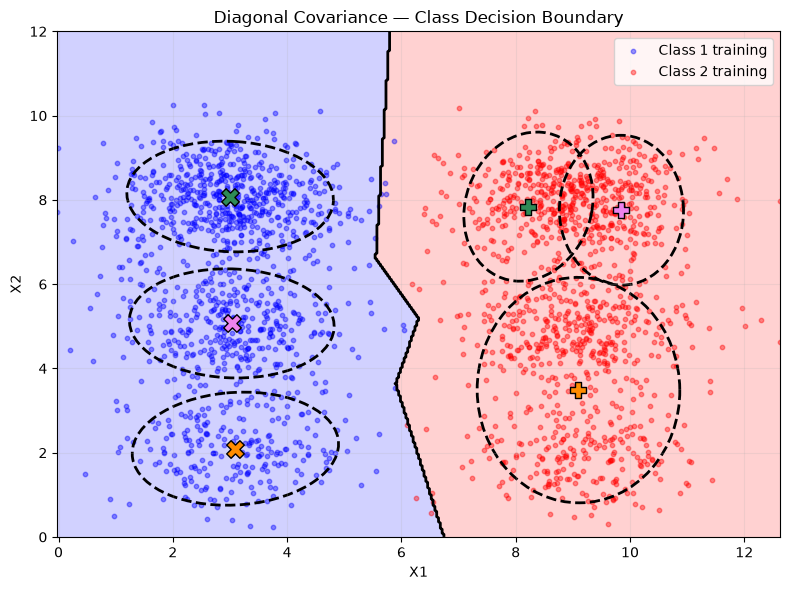

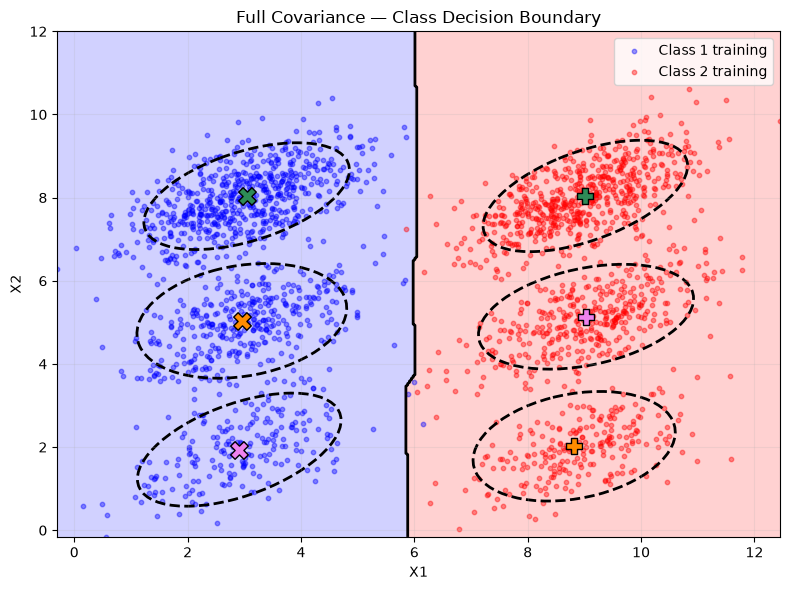

In [25]:
from matplotlib.patches import Ellipse

for cov_type in covariance_types:

    X1_train = datasets[cov_type]["X1_train"]
    X2_train = datasets[cov_type]["X2_train"]

    centroids1 = cluster_results[cov_type]["centroids1"]
    centroids2 = cluster_results[cov_type]["centroids2"]

    labels1 = cluster_results[cov_type]["labels1"]
    labels2 = cluster_results[cov_type]["labels2"]

    X_train = np.vstack((X1_train, X2_train))

    x_min = min(X_train[:, 0].min(), 0)
    x_max = max(X_train[:, 0].max(), 12)
    y_min = min(X_train[:, 1].min(), 0)
    y_max = max(X_train[:, 1].max(), 12)

    xx, yy = np.meshgrid(
        np.linspace(x_min, x_max, 400),
        np.linspace(y_min, y_max, 400)
    )

    grid = np.column_stack((xx.ravel(), yy.ravel()))

    predictions, _, _ = classify_by_distortion(
        grid, centroids1, centroids2
    )

    regions = predictions.reshape(xx.shape)

    fig, ax = plt.subplots(figsize=(8, 6))

    ax.contourf(
        xx, yy, regions,
        levels=[-0.5, 0.5, 1.5],
        colors=class_colors,
        alpha=0.18
    )

    ax.contour(
        xx, yy, regions,
        levels=[0.5],
        colors="black",
        linewidths=2
    )

    ax.scatter(
        X1_train[:, 0], X1_train[:, 1],
        s=10,
        color=class_colors[0],
        alpha=0.4,
        label="Class 1 training"
    )

    ax.scatter(
        X2_train[:, 0], X2_train[:, 1],
        s=10,
        color=class_colors[1],
        alpha=0.4,
        label="Class 2 training"
    )

    for j in range(K):

        points1 = X1_train[labels1 == j]
        points2 = X2_train[labels2 == j]

        for points in [points1, points2]:

            if len(points) > 2:

                mean = np.mean(points, axis=0)
                cov = np.cov(points, rowvar=False)

                eigenvalues, eigenvectors = np.linalg.eigh(cov)
                order = np.argsort(eigenvalues)[::-1]

                eigenvalues = eigenvalues[order]
                eigenvectors = eigenvectors[:, order]

                angle = np.degrees(
                    np.arctan2(
                        eigenvectors[1, 0],
                        eigenvectors[0, 0]
                    )
                )

                width, height = 2 * 1.8 * np.sqrt(
                    np.maximum(eigenvalues, 0)
                )

                ellipse = Ellipse(
                    xy=mean,
                    width=width,
                    height=height,
                    angle=angle,
                    fill=False,
                    edgecolor="black",
                    linewidth=2,
                    linestyle="--"
                )

                ax.add_patch(ellipse)

        ax.scatter(
            centroids1[j, 0], centroids1[j, 1],
            marker="X",
            s=160,
            color=component_colors[j],
            edgecolor="black",
            zorder=5
        )

        ax.scatter(
            centroids2[j, 0], centroids2[j, 1],
            marker="P",
            s=130,
            color=component_colors[j],
            edgecolor="black",
            zorder=5
        )

    ax.set_title(
        f"{cov_type.title()} Covariance — Class Decision Boundary"
    )

    ax.set_xlabel("X1")
    ax.set_ylabel("X2")

    ax.set_xlim(x_min, x_max)
    ax.set_ylim(y_min, y_max)

    ax.set_xticks(np.arange(np.ceil(x_min / 2) * 2, x_max + 1, 2))
    ax.set_yticks(np.arange(np.ceil(y_min / 2) * 2, y_max + 1, 2))

    ax.legend()
    ax.grid(alpha=0.2)

    plt.tight_layout()
    plt.show()

In [26]:
print(
    f"{'Covariance':<15}"
    f"{'Accuracy (%)':<18}"
    f"{'Correct':<12}"
    f"{'Incorrect':<12}"
)

print("-" * 57)

for cov_type in covariance_types:

    accuracy = results[cov_type]["accuracy"]
    confusion = results[cov_type]["confusion"]

    correct = np.trace(confusion)
    incorrect = np.sum(confusion) - correct

    print(
        f"{cov_type.title():<15}"
        f"{accuracy:<18.2f}"
        f"{correct:<12}"
        f"{incorrect:<12}"
    )

Covariance     Accuracy (%)      Correct     Incorrect   
---------------------------------------------------------
Isotropic      99.67             598         2           
Diagonal       99.83             599         1           
Full           100.00            600         0           
